This notebook contains code to generate figures 1, 2 in the paper.

In [45]:
FIGSIZE = (8, 3)

In [46]:
from pathlib import Path
import sys
sys.path.append(str(Path('.').resolve().parent / 'src'))

In [47]:
from preprocessing import load_preprocessed_corpus

preprocessed_corpus_path = Path('.').resolve().parent / "output" / "preprocessed_conllu_corpus.json"
data = load_preprocessed_corpus(preprocessed_corpus_path, max_issues_per_date=10)

In [48]:
import numpy as np
from collections import defaultdict

# Reference decade distribution (absolute issue counts) to match.
ref = np.array(
    [174177, 243572, 306121, 307531, 133070,
     200329, 208536, 212615, 223314, 226992.]
)

by_decade = defaultdict(list)
for issue in data:
    by_decade[(issue['year'] // 10) * 10].append(issue)

decades = sorted(by_decade)
assert len(decades) == len(ref), 'decade count does not match reference'

available = np.array([len(by_decade[d]) for d in decades], dtype=float)
ref_frac = ref / ref.sum()

scale = min(available[i] / ref_frac[i] for i in range(len(decades)))
targets = np.floor(scale * ref_frac).astype(int)

rng = np.random.default_rng(0)
downsampled = []
for d, n in zip(decades, targets):
    pool = by_decade[d]
    idx = rng.choice(len(pool), size=n, replace=False)
    downsampled.extend(pool[i] for i in idx)

data = downsampled
len(data)

32375

In [49]:
from orthography_change.rules.loader import (
    load_rules_by_old_form, load_rules_by_new_form,
)
from config import RULES_FILE, AGGREGATION_MONTHS
from orthography_change.analyzer import OrthographyAnalyzer
from orthography_change.statistics import Statistics
from orthography_change.adoption import AdoptionCalculator

old_index = load_rules_by_old_form(RULES_FILE)
new_index = load_rules_by_new_form(RULES_FILE)
analyzer = OrthographyAnalyzer(old_index, new_index)
results = [analyzer.analyze_from_cache(issue) for issue in data]

stat = Statistics()
df_combined = stat.aggregate_by_period(results, months=AGGREGATION_MONTHS)
df = df_combined

calc = AdoptionCalculator()

Aggregating: 100%|██████████| 32375/32375 [00:00<00:00, 99698.24it/s] 


In [50]:
import config
from language_classification import attach_labels, load_classified_corpus

classified_issues = load_classified_corpus(config.CLASSIFIED_CACHE)
attach_labels(results, classified_issues)

bokmaal_labels = config.LANGUAGE_LABEL_GROUPS["bokmaal_dan"]
nynorsk_labels = config.LANGUAGE_LABEL_GROUPS["nynorsk"]

df_bokmaal = stat.aggregate_by_period(
    [r for r in results if r["label"] in bokmaal_labels],
    months=AGGREGATION_MONTHS,
)
df_nynorsk = stat.aggregate_by_period(
    [r for r in results if r["label"] in nynorsk_labels],
    months=AGGREGATION_MONTHS,
)

len(df_bokmaal), len(df_nynorsk)

Aggregating: 100%|██████████| 1485/1485 [00:00<00:00, 98851.62it/s]


(200, 179)

In [51]:
import pandas as pd

rules_df = pd.read_csv(RULES_FILE)

convergence_pairs = []
for new_form, group in rules_df.groupby("new_form"):
    languages = set(group["language"])
    if not {"nb", "nn"}.issubset(languages):
        continue
    nb_old_form = group.loc[group["language"] == "nb", "old_form"].iloc[0]
    nn_old_form = group.loc[group["language"] == "nn", "old_form"].iloc[0]
    convergence_pairs.append((new_form, nb_old_form, nn_old_form))

convergence_pairs

[('dråpe', 'draabe', 'drope'), ('mellom', 'mellem', 'millom')]

## Figure grid

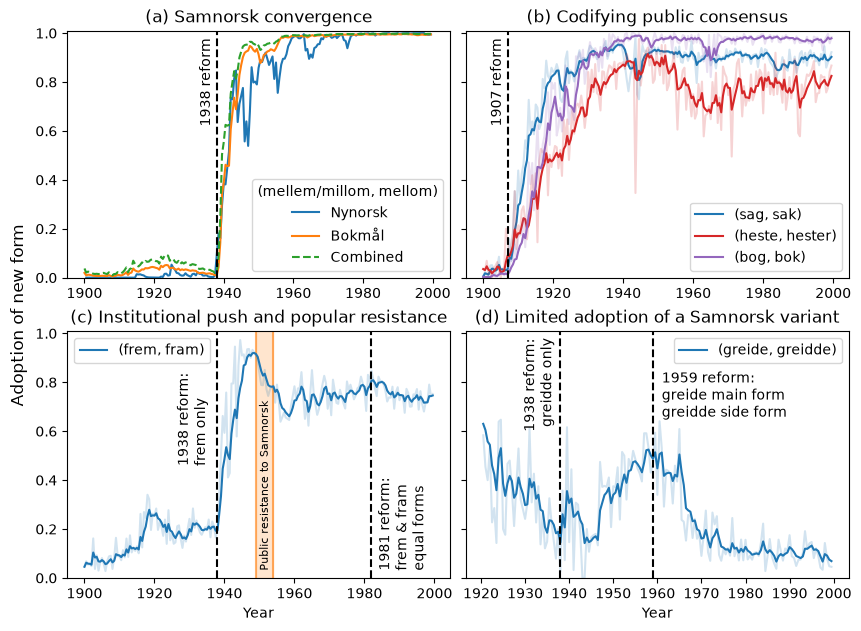

In [52]:
import matplotlib.pyplot as plt

# One 2x2 figure for Figures 2-5, included at \textwidth (15 cm). At 8.5 in
# wide it is scaled by ~0.69, so the default 10 pt text prints at ~7 pt.
GRIDSIZE = (8.5, 6.2)
ewma_span, raw_alpha = 5, 0.2


def plot_pair(ax, old, new, c='tab:blue', min_period=None):
    """Plot raw and EWMA-smoothed adoption of new over old.

    Args:
        ax (matplotlib.axes.Axes): Axes to draw on.
        old (str): Old form.
        new (str): New form.
        c (str): Line color.
        min_period (float): If given, keep only periods after this value.
    """
    for use_ewma, alpha in [(False, raw_alpha), (True, 1)]:
        curve = calc.compute_curve(df, old_form=old, new_form=new,
                                   use_ewma=use_ewma, ewma_span=ewma_span)
        if min_period is not None:
            curve = curve[curve['period'] > min_period]
        ax.plot(curve['period'], curve['adoption'], c=c, alpha=alpha,
                label=f'({old}, {new})' if use_ewma else None)


# Figure 2 data: mellom replaces mellem (Bokmål) and millom (Nynorsk).
new_form, nb_old_form, nn_old_form = ('mellom', 'mellem', 'millom')
nn_curve = calc.compute_curve(df_nynorsk, old_form=nn_old_form,
                              new_form=new_form, use_ewma=True)
nb_curve = calc.compute_curve(df_bokmaal, old_form=nb_old_form,
                              new_form=new_form, use_ewma=True)
combined_curve = calc.compute_meta_curve(
    [calc.compute_curve(df_combined, old_form=o, new_form=new_form,
                        use_ewma=False) for o in (nb_old_form, nn_old_form)],
    use_ewma=True)

fig, axes = plt.subplots(2, 2, figsize=GRIDSIZE, sharey=True,
                         layout='constrained')
(ax2, ax5), (ax3, ax4) = axes

# (a) Figure 2: Bokmål and Nynorsk users jointly adopt mellom.
ax2.plot(nn_curve['period'], nn_curve['adoption'], label='Nynorsk',
         c='tab:blue')
ax2.plot(nb_curve['period'], nb_curve['adoption'], label='Bokmål',
         c='tab:orange')
ax2.plot(combined_curve['period'], combined_curve['adoption'],
         label='Combined', c='tab:green', linestyle='dashed')
ax2.axvline(1938, c='k', linestyle='dashed')
ax2.text(1937, 0.98, '1938 reform', ha='right', va='top', rotation=90)
ax2.set_title('(a) Samnorsk convergence')
ax2.legend(loc='lower right', title='(mellem/millom, mellom)')

# (b) Figure 5: codifying public consensus.
for old, new, c in [('sag', 'sak', 'tab:blue'),
                    ('heste', 'hester', 'tab:red'),
                    ('bog', 'bok', 'tab:purple')]:
    plot_pair(ax5, old, new, c=c)
ax5.axvline(1907, c='k', linestyle='dashed')
ax5.text(1906, 0.98, '1907 reform', ha='right', va='top', rotation=90)
ax5.set_title('(b) Codifying public consensus')
ax5.legend(loc='lower right')

# (c) Figure 3: institutional push and popular resistance.
plot_pair(ax3, 'frem', 'fram')
ax3.axvline(1938, c='k', linestyle='dashed')
ax3.text(1936 - 10, 0.84, '1938 reform:\nfrem only',
         ha='left', va='top', rotation=90)
ax3.axvline(1982, c='k', linestyle='dashed')
ax3.text(1983.5, 0.03, '1981 reform:\nfrem & fram\nequal forms', ha='left',
         va='bottom', rotation=90)
ax3.axvline(1949, c='tab:orange', alpha=0.6, zorder=-1)
ax3.axvline(1954, c='tab:orange', alpha=0.6, zorder=-1)
ax3.fill_between([1949, 1954], 0, 1.2, alpha=0.2, color='tab:orange')
ax3.text(1951.5, 0.03, 'Public resistance to Samnorsk', ha='center',
         va='bottom', rotation=90, fontsize=8)
ax3.set_title('(c) Institutional push and popular resistance')
ax3.legend(loc='upper left')

# (d) Figure 4: greidde enforced in 1938, demoted to side form in 1959.
plot_pair(ax4, 'greide', 'greidde', min_period=1920)
ax4.axvline(1938, c='k', linestyle='dashed')
ax4.axvline(1959, c='k', linestyle='dashed')
ax4.text(1937, 0.98, '1938 reform:\ngreidde only', ha='right', va='top',
         rotation=90)
ax4.text(1961, 0.85, '1959 reform:\ngreide main form\ngreidde side form',
         ha='left', va='top')
ax4.set_title('(d) Limited adoption of a Samnorsk variant')
ax4.legend(loc='upper right')

ax2.set_ylim(0, 1.01)
ax2.set_xlim(1895, 2005)
for ax in axes[1]:
    ax.set_xlabel('Year')
fig.supylabel('Adoption of new form')
fig.savefig('paired-adoption-grid.pdf', bbox_inches='tight', dpi=600)
plt.show()

# Time-to-adoption computation

In [53]:
import pandas as pd

_forms = pd.read_csv(Path('.').resolve().parent / "data" / "rules.csv")
_forms = _forms[(_forms['status_before'] == 'main_form') &
                (_forms['status_after'] == 'main_form')]
_forms = _forms[['effective_year', 'language', 'old_form', 'new_form']]
_forms = _forms.rename({'effective_year': 'reform_year'}, axis=1)

In [54]:
# Pairs never observed after their reform have undefined adoption. They are
# missing data, not censored at the corpus end, so they are dropped.
curves = dict()
for index, row in _forms.iterrows():
    curve = calc.compute_curve(
        df,
        old_form=row['old_form'],
        new_form=row['new_form'],
        ewma_span=20,
        use_ewma=True
    )
    _post = curve[curve['period'] >= row['reform_year']]
    if _post['adoption'].notna().any():
        curves[index] = curve
    else:
        print(f"Dropped ({row['reform_year']}): "
              f"{row['old_form']} -> {row['new_form']}")
_forms = _forms.loc[list(curves)].copy()

Dropped (1901): visorna -> visorne
Dropped (1917): ei visa -> ei vise


In [55]:
import numpy as np


def _tta_pair(pair: pd.DataFrame, start_year: float, threshold: float):
    """Compute time-to-adoption for a word pair (accounts for censoring).

    Args:
        pair (pd.DataFrame): Adoption curve with columns
            'period' and 'adoption'.
        start_year (float): Reform year to measure time from.
        threshold (float): Adoption level defining the event.

    Returns:
        tuple[float, bool]: Time to adoption in years, and whether adoption was 
            observed.
    """
    _subset = pair[pair['period'] >= start_year]
    if _subset.empty:
        return np.nan, False
    for _, row in _subset.iterrows():
        if row['adoption'] >= threshold:
            return row['period'] - start_year, True
    return _subset['period'].max() - start_year, False


TARGETS = list(range(0, 100, 1))
for target in TARGETS:
    _tta = [_tta_pair(
        val, start_year=_forms.loc[key, 'reform_year'],
        threshold=target / 100
    ) for key, val in curves.items()]
    _forms[f'tta_{target}'] = [t for t, _ in _tta]
    _forms[f'tta_{target}_event'] = [e for _, e in _tta]

C:\Users\david\AppData\Local\Temp\ipykernel_4748\3374584089.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  _forms[f'tta_{target}_event'] = [e for _, e in _tta]
C:\Users\david\AppData\Local\Temp\ipykernel_4748\3374584089.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  _forms[f'tta_{target}'] = [t for t, _ in _tta]


In [56]:
def _kaplan_meier_rmst(times: np.ndarray, events: np.ndarray, tau: float):
    """Restricted mean survival time via Kaplan-Meier.

    Args:
        times (np.ndarray): Event/censoring times with shape (n,).
        events (np.ndarray): True where the adoption target was
            observed to be reached. Has shape (n,).
        tau (float): Restriction horizon for the integral.

    Returns:
        float: Restricted mean survival time up to tau.
    """
    order = np.argsort(times)
    t, e = times[order], events[order]
    surv, prev_t, rmst = 1.0, 0.0, 0.0
    for ut in np.unique(t[t <= tau]):
        rmst += surv * (ut - prev_t)
        at_risk = np.sum(t >= ut)
        deaths = np.sum((t == ut) & e)
        surv *= (1 - deaths / at_risk)
        prev_t = ut
    rmst += surv * (tau - prev_t)
    return rmst


def _bootstrap_rmst(times: np.ndarray,
                    events: np.ndarray,
                    tau: float,
                    n_boot: int = 2000,
                    ci: float = 0.95,
                    seed: int = 0):
    """Bootstrap CI for the Kaplan-Meier RMST.

    Args:
        times (np.ndarray): Adoption/censoring times with shape (n,).
        events (np.ndarray): Adoption flags with shape (n,).
        tau (float): Restriction horizon, fixed across resamples.
        n_boot (int): Number of bootstrap resamples.
        ci (float): Confidence level, e.g. 0.95 for a 95% CI.
        seed (int): RNG seed for reproducibility.

    Returns:
        tuple[float, float]: Lower and upper CI bounds.
    """
    rng = np.random.default_rng(seed)
    n = len(times)
    if n < 2:
        return np.nan, np.nan
    idx = rng.integers(0, n, size=(n_boot, n))
    boot = [_kaplan_meier_rmst(times[i], events[i], tau) for i in idx]
    alpha = (1 - ci) / 2
    lo, hi = np.nanpercentile(boot, [100 * alpha, 100 * (1 - alpha)])
    return float(lo), float(hi)


res_list = []
for target in TARGETS:
    print(f'{target=}')
    rows = []
    for ry, sub in _forms.groupby('reform_year'):
        times = sub[f'tta_{target}'].to_numpy(dtype=float)
        events = sub[f'tta_{target}_event'].to_numpy(dtype=bool)
        mask = ~np.isnan(times)
        times, events = times[mask], events[mask]
        if len(times) == 0:
            rows.append((ry, np.nan, np.nan, np.nan))
            continue
        tau = times.max()
        rmst = _kaplan_meier_rmst(times, events, tau)
        lo, hi = _bootstrap_rmst(times, events, tau, ci=0.75)
        rows.append((ry, rmst, lo, hi))
    tmp = pd.DataFrame(
        rows, columns=['reform_year', 'tta', 'ci_lower', 'ci_upper']
    )
    tmp['target'] = target
    res_list.append(tmp)

target=0
target=1
target=2
target=3
target=4
target=5
target=6
target=7
target=8
target=9
target=10
target=11
target=12
target=13
target=14
target=15
target=16
target=17
target=18
target=19
target=20
target=21
target=22
target=23
target=24
target=25
target=26
target=27
target=28
target=29
target=30
target=31
target=32
target=33
target=34
target=35
target=36
target=37
target=38
target=39
target=40
target=41
target=42
target=43
target=44
target=45
target=46
target=47
target=48
target=49
target=50
target=51
target=52
target=53
target=54
target=55
target=56
target=57
target=58
target=59
target=60
target=61
target=62
target=63
target=64
target=65
target=66
target=67
target=68
target=69
target=70
target=71
target=72
target=73
target=74
target=75
target=76
target=77
target=78
target=79
target=80
target=81
target=82
target=83
target=84
target=85
target=86
target=87
target=88
target=89
target=90
target=91
target=92
target=93
target=94
target=95
target=96
target=97
target=98
target=99


## Figure 1

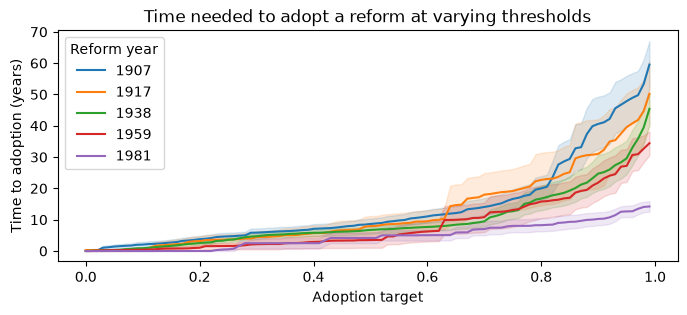

In [57]:
tmp = pd.concat(res_list, axis=0, ignore_index=True)
fig, ax = plt.subplots(figsize=FIGSIZE)
for ry in tmp['reform_year'].unique():
    if ry != 1901:
        ss = tmp[tmp['reform_year'] == ry]
        if ry == 1982:
            ry = 1981
        line, = ax.plot(ss['target'] / 100, ss['tta'], label=f'{int(ry)}')
        ax.fill_between(ss['target'] / 100, ss['ci_lower'], ss['ci_upper'],
                        color=line.get_color(), alpha=0.15)
ax.legend(title='Reform year')
ax.set_xlabel('Adoption target')
ax.set_ylabel('Time to adoption (years)')
ax.set_title('Time needed to adopt a reform at varying thresholds')
fig.savefig('time-to-adoption.pdf', bbox_inches='tight', dpi=600)
plt.show()

In [58]:
print(tmp[tmp['target'] == 90][['reform_year', 'tta']].reset_index(drop=True))

   reform_year        tta
0         1901   2.000000
1         1907  40.590909
2         1917  31.000000
3         1938  24.714286
4         1959  21.846154
5         1982  10.238095
